# Breast Cancer Classification - ML Assignment 2

**Student ID:** 2026AJ05227

## Problem Statement
Build and evaluate multiple machine learning classification models to predict whether a breast tumor is **Malignant (M)** or **Benign (B)** based on features computed from digitized images of fine needle aspirate (FNA) of breast masses.

**Dataset:** Breast Cancer Wisconsin (Diagnostic) Dataset  
**Models:** Logistic Regression, Decision Tree, KNN, Naive Bayes, Support Vector Machine

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import json
import os
import warnings
warnings.filterwarnings('ignore')

# Scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score,
    recall_score, f1_score, matthews_corrcoef,
    confusion_matrix, classification_report, roc_curve
)
import joblib

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('Set2')
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11

print('All libraries imported successfully!')

All libraries imported successfully!


## 2. Load Dataset

In [2]:
data = pd.read_csv(r"c:\Users\Manasa_Reddy\Downloads\breast cancer.csv")

# Drop the trailing empty column (caused by trailing comma in CSV)
data = data.loc[:, ~data.columns.str.match(r"^Unnamed")]
if "" in data.columns:
    data = data.drop(columns=[""])

print(f"Dataset shape: {data.shape}")
print(f"\nFirst 5 rows:")
data.head()

Dataset shape: (569, 32)

First 5 rows:


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 3. Exploratory Data Analysis (EDA)

### 3.1 Dataset Info & Statistics

In [3]:
print("Dataset Information:")
print("="*50)
data.info()

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perim

In [4]:
print("Statistical Summary:")
data.describe().T

Statistical Summary:


,count,mean,std,min,25%,50%,75%,max
id,569.0,3.037183e+07,1.250206e+08,8670.000000,869218.000000,906024.000000,8.813129e+06,9.113205e+08
radius_mean,569.0,1.412729e+01,3.524049e+00,6.981000,11.700000,13.370000,1.578000e+01,2.811000e+01
texture_mean,569.0,1.928965e+01,4.301036e+00,9.710000,16.170000,18.840000,2.180000e+01,3.928000e+01
perimeter_mean,569.0,9.196903e+01,2.429898e+01,43.790000,75.170000,86.240000,1.041000e+02,1.885000e+02
area_mean,569.0,6.548891e+02,3.519141e+02,143.500000,420.300000,551.100000,7.827000e+02,2.501000e+03
smoothness_mean,569.0,9.636028e-02,1.406413e-02,0.052630,0.086370,0.095870,1.053000e-01,1.634000e-01
compactness_mean,569.0,1.043410e-01,5.281276e-02,0.019380,0.064920,0.092630,1.304000e-01,3.454000e-01
concavity_mean,569.0,8.879932e-02,7.971981e-02,0.000000,0.029560,0.061540,1.307000e-01,4.268000e-01
concave points_mean,569.0,4.891915e-02,3.880284e-02,0.000000,0.020310,0.033500,7.400000e-02,2.012000e-01
symmetry_mean,569.0,1.811619e-01,2.741428e-02,0.106000,0.161900,0.179200,1.957000e-01,3.040000e-01


In [5]:
# Check for missing values
print("Missing Values:")
print(data.isnull().sum().sum(), "total missing values")
print("\nDuplicate Rows:", data.duplicated().sum())

Missing Values:
0 total missing values

Duplicate Rows: 0


### 3.2 Target Variable Distribution

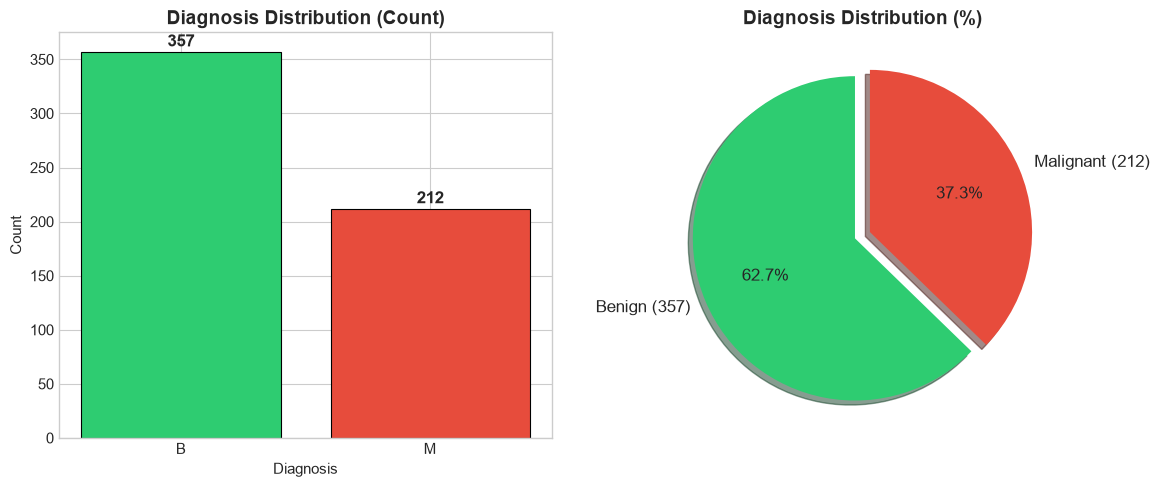


Class Distribution:
diagnosis
B    357
M    212
Name: count, dtype: int64

Benign: 357 (62.7%)
Malignant: 212 (37.3%)


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Count plot
colors = ['#2ecc71', '#e74c3c']
diagnosis_counts = data['diagnosis'].value_counts()
axes[0].bar(diagnosis_counts.index, diagnosis_counts.values, color=colors, edgecolor='black', linewidth=0.8)
axes[0].set_title('Diagnosis Distribution (Count)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Diagnosis')
axes[0].set_ylabel('Count')
for i, (label, count) in enumerate(zip(diagnosis_counts.index, diagnosis_counts.values)):
    axes[0].text(i, count + 5, str(count), ha='center', fontsize=12, fontweight='bold')

# Pie chart
axes[1].pie(diagnosis_counts.values, labels=[f'Benign ({diagnosis_counts["B"]})', f'Malignant ({diagnosis_counts["M"]})'],
            autopct='%1.1f%%', colors=colors, startangle=90,
            explode=(0.05, 0.05), shadow=True, textprops={'fontsize': 12})
axes[1].set_title('Diagnosis Distribution (%)', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

print(f"\nClass Distribution:")
print(data['diagnosis'].value_counts())
print(f"\nBenign: {diagnosis_counts['B']} ({diagnosis_counts['B']/len(data)*100:.1f}%)")
print(f"Malignant: {diagnosis_counts['M']} ({diagnosis_counts['M']/len(data)*100:.1f}%)")

### 3.3 Feature Distributions

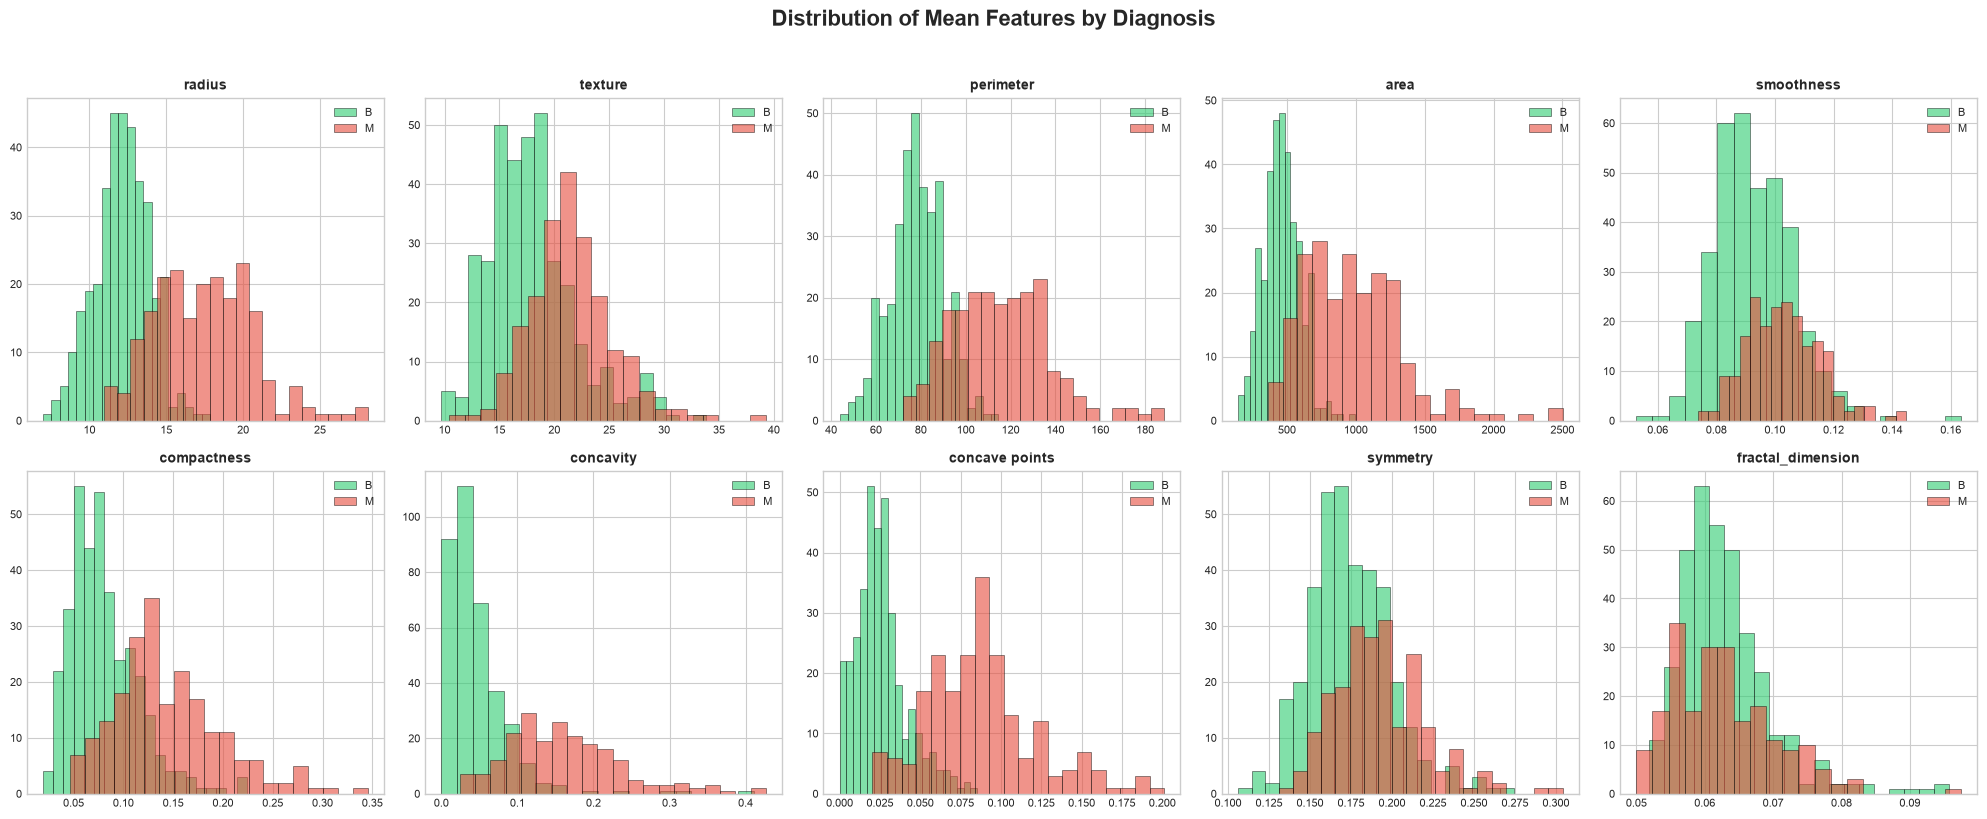

In [7]:
# Distribution of mean features by diagnosis
mean_features = [col for col in data.columns if '_mean' in col]

fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for i, feature in enumerate(mean_features):
    for label, color in zip(['B', 'M'], ['#2ecc71', '#e74c3c']):
        subset = data[data['diagnosis'] == label][feature]
        axes[i].hist(subset, bins=20, alpha=0.6, color=color, label=label, edgecolor='black', linewidth=0.5)
    axes[i].set_title(feature.replace('_mean', ''), fontsize=10, fontweight='bold')
    axes[i].legend(fontsize=8)
    axes[i].tick_params(labelsize=8)

plt.suptitle('Distribution of Mean Features by Diagnosis', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 3.4 Correlation Heatmap

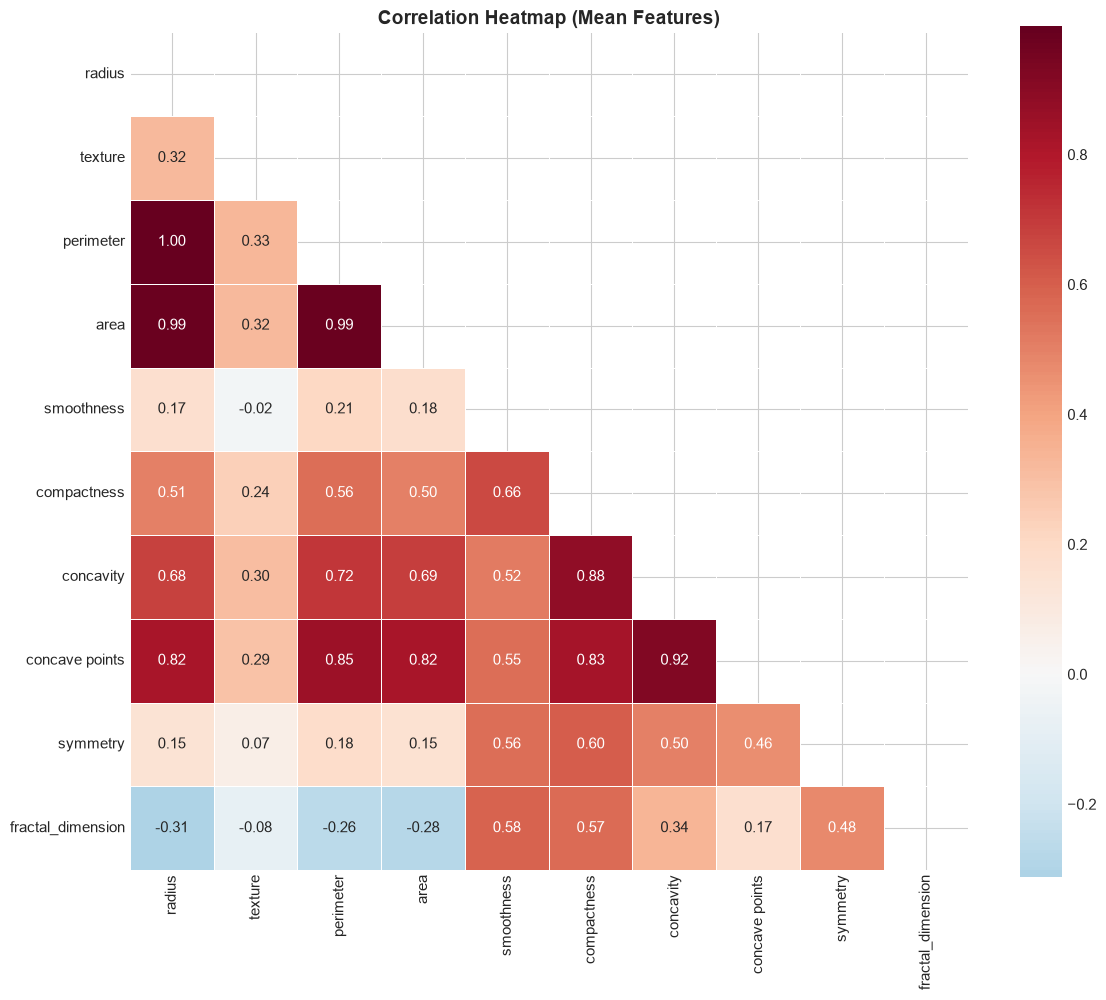

In [8]:
# Correlation heatmap for mean features
mean_cols = [col for col in data.columns if '_mean' in col]
corr_matrix = data[mean_cols].corr()

fig, ax = plt.subplots(figsize=(12, 10))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, square=True, linewidths=0.5, ax=ax,
            xticklabels=[c.replace('_mean', '') for c in mean_cols],
            yticklabels=[c.replace('_mean', '') for c in mean_cols])
ax.set_title('Correlation Heatmap (Mean Features)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 3.5 Box Plots - Key Features

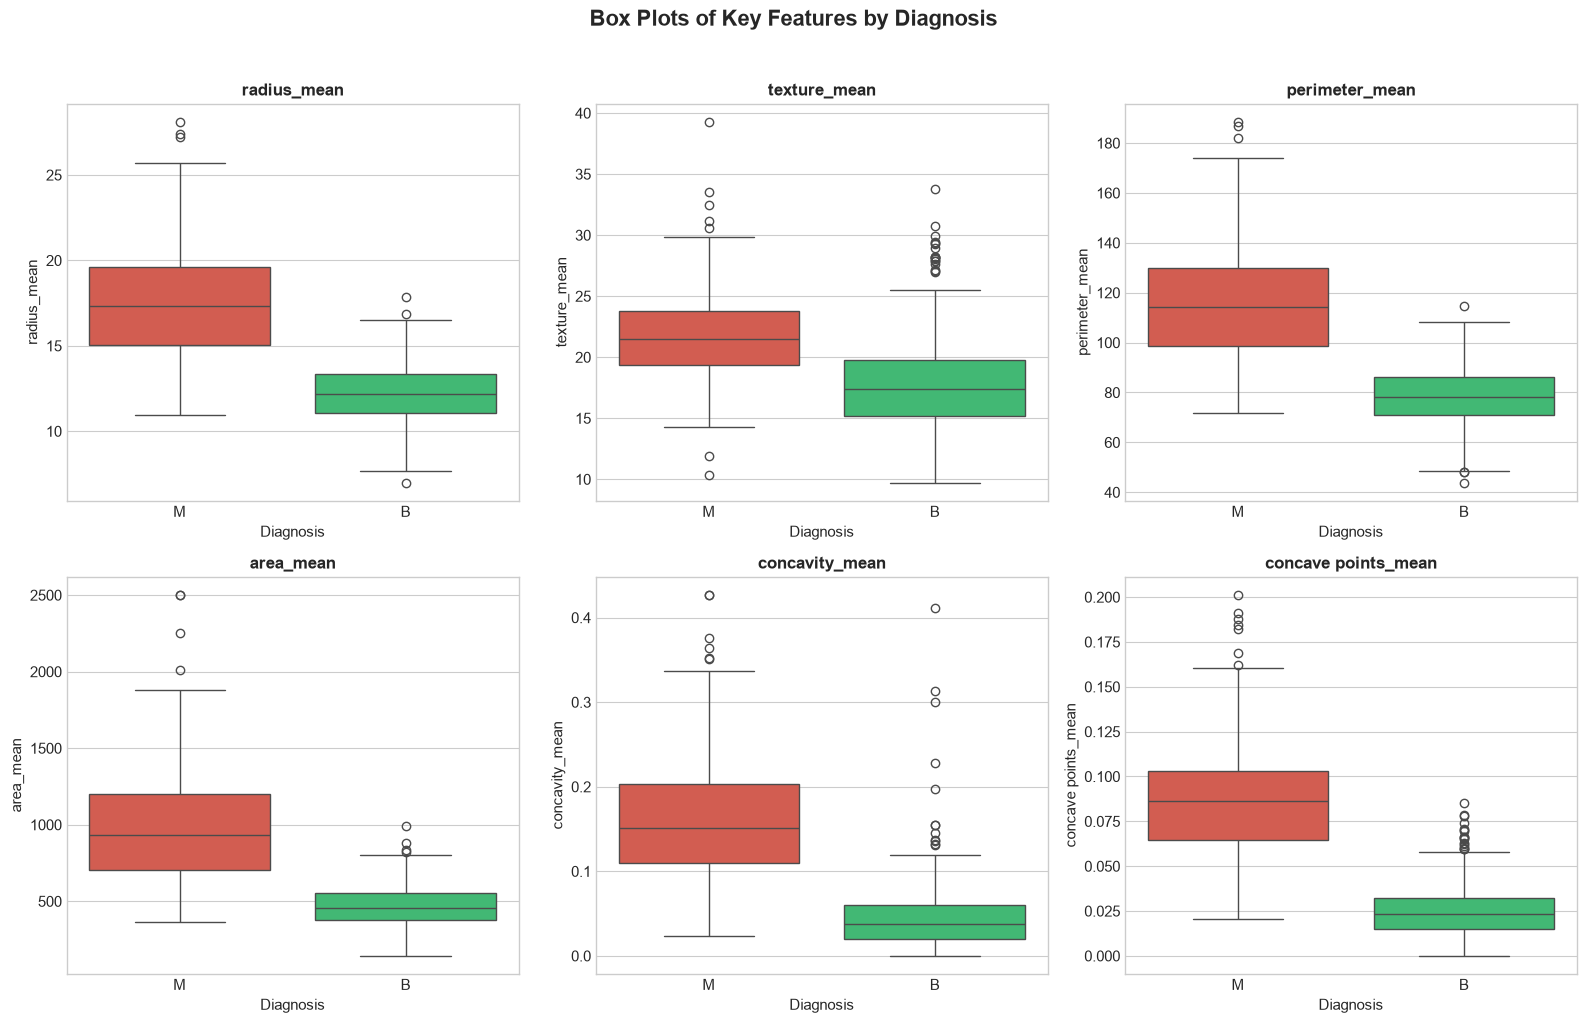

In [9]:
key_features = ['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean',
                'concavity_mean', 'concave points_mean']

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, feature in enumerate(key_features):
    sns.boxplot(x='diagnosis', y=feature, data=data, ax=axes[i],
                palette={'B': '#2ecc71', 'M': '#e74c3c'})
    axes[i].set_title(feature, fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Diagnosis')

plt.suptitle('Box Plots of Key Features by Diagnosis', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 3.6 Pairplot of Top Features

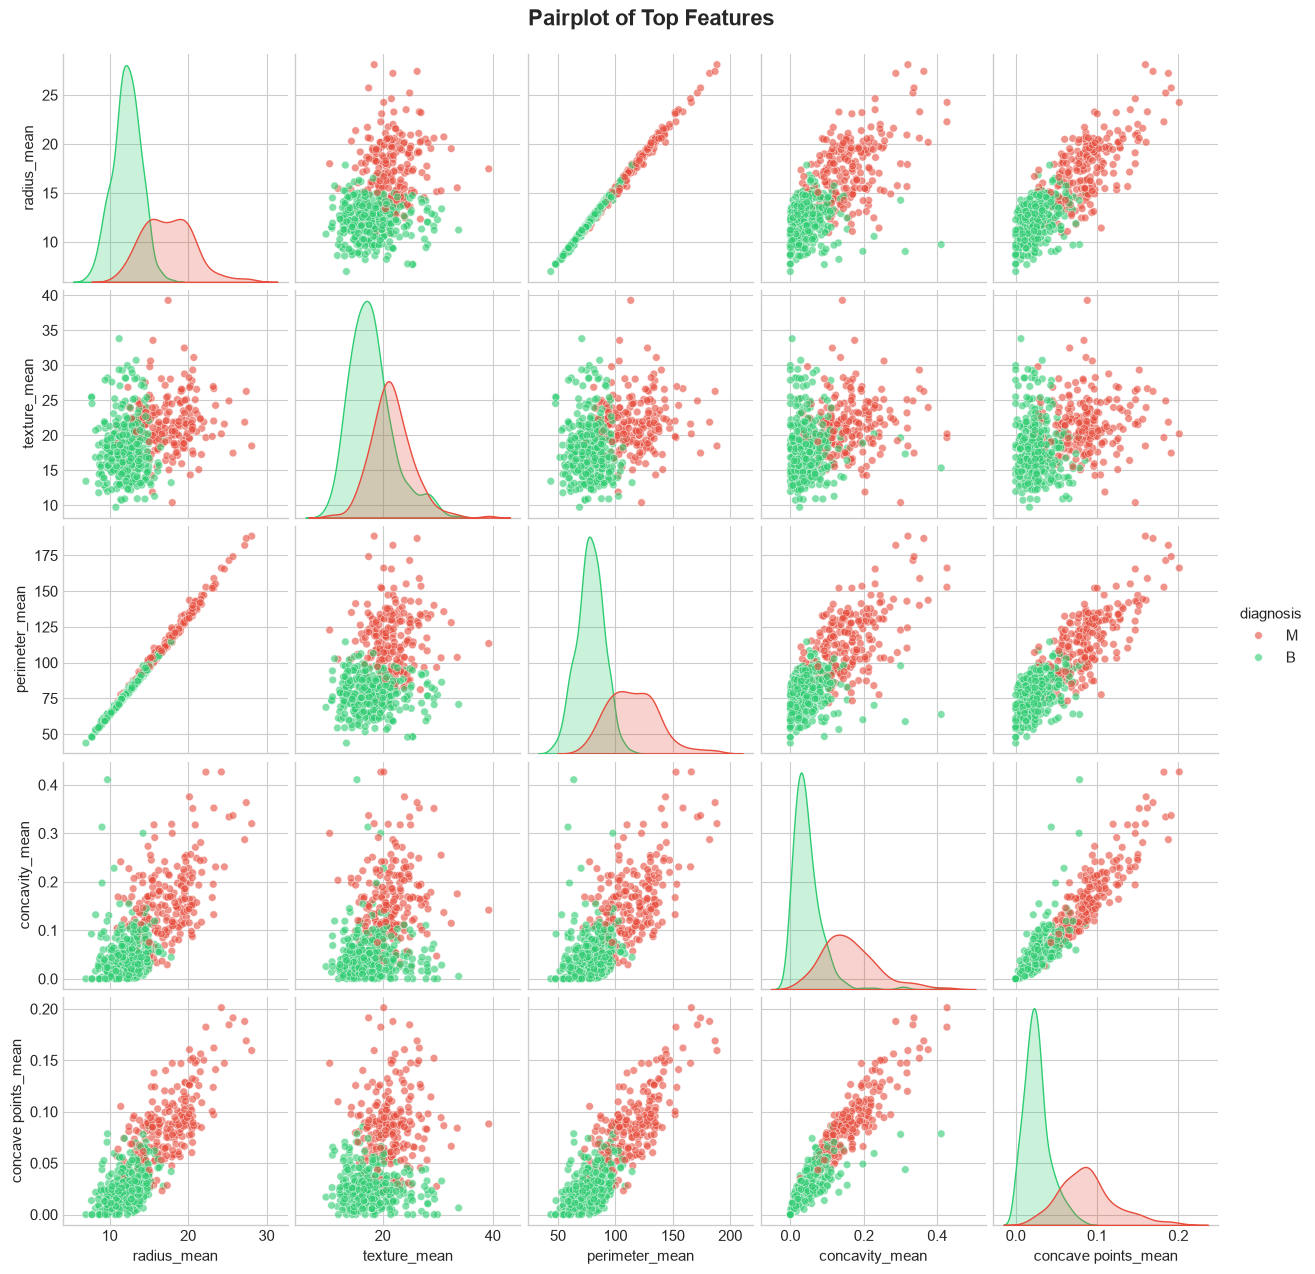

In [10]:
top_features = ['radius_mean', 'texture_mean', 'perimeter_mean',
                'concavity_mean', 'concave points_mean', 'diagnosis']

g = sns.pairplot(data[top_features], hue='diagnosis',
                 palette={'B': '#2ecc71', 'M': '#e74c3c'},
                 diag_kind='kde', plot_kws={'alpha': 0.6, 's': 30})
g.figure.suptitle('Pairplot of Top Features', fontsize=16, fontweight='bold', y=1.02)
plt.show()

## 4. Data Preprocessing

In [11]:
# Encode target variable
le = LabelEncoder()
data['diagnosis'] = le.fit_transform(data['diagnosis'])  # B=0, M=1
print(f"Label mapping: {dict(zip(le.classes_, le.transform(le.classes_)))}")

# Separate features and target
X = data.drop(columns=['id', 'diagnosis'])
y = data['diagnosis']

print(f"\nFeatures shape: {X.shape}")
print(f"Target shape: {y.shape}")
print(f"Feature columns ({len(X.columns)}): {list(X.columns)}")

Label mapping: {'B': np.int64(0), 'M': np.int64(1)}

Features shape: (569, 30)
Target shape: (569,)
Feature columns (30): ['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst']


In [12]:
# Train/Test split (80/20, stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Test set: {X_test.shape[0]} samples")
print(f"\nTraining set class distribution:")
print(y_train.value_counts())
print(f"\nTest set class distribution:")
print(y_test.value_counts())

Training set: 455 samples
Test set: 114 samples

Training set class distribution:
diagnosis
0    285
1    170
Name: count, dtype: int64

Test set class distribution:
diagnosis
0    72
1    42
Name: count, dtype: int64


In [13]:
# Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Save scaler and encoder
os.makedirs('model', exist_ok=True)
joblib.dump(scaler, os.path.join('model', 'scaler.pkl'))
joblib.dump(le, os.path.join('model', 'label_encoder.pkl'))
print('Scaler and LabelEncoder saved.')

# Save test data CSV
test_indices = X_test.index
test_data = data.loc[test_indices].copy()
test_data['diagnosis'] = le.inverse_transform(test_data['diagnosis'])
test_data.to_csv('test_data.csv', index=False)
print(f'Test data saved: test_data.csv ({test_data.shape[0]} rows)')

Scaler and LabelEncoder saved.
Test data saved: test_data.csv (114 rows)


## 5. Model Training & Evaluation

In [14]:
# Define models
models = {
    'Logistic Regression': LogisticRegression(max_iter=10000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'Naive Bayes': GaussianNB(),
    'Support Vector Machine': SVC(kernel='rbf', probability=True, random_state=42),
}

# Storage for results
results = {}
predictions = {}  # store predictions for later visualization
probabilities = {}  # store probabilities for ROC curves

### 5.1 Logistic Regression

In [15]:
name = 'Logistic Regression'
model = models[name]
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

predictions[name] = y_pred
probabilities[name] = y_prob

acc = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
mcc = matthews_corrcoef(y_test, y_pred)

results[name] = {
    'Accuracy': round(acc, 4), 'AUC': round(auc, 4),
    'Precision': round(prec, 4), 'Recall': round(rec, 4),
    'F1': round(f1, 4), 'MCC': round(mcc, 4)
}

print(f"{'='*60}")
print(f"  {name}")
print(f"{'='*60}")
print(f"  Accuracy : {acc:.4f}")
print(f"  AUC      : {auc:.4f}")
print(f"  Precision: {prec:.4f}")
print(f"  Recall   : {rec:.4f}")
print(f"  F1 Score : {f1:.4f}")
print(f"  MCC      : {mcc:.4f}")
print(f"\nConfusion Matrix:\n{confusion_matrix(y_test, y_pred)}")
print(f"\nClassification Report:\n{classification_report(y_test, y_pred, target_names=le.classes_)}")

# Save model
joblib.dump(model, os.path.join('model', 'logistic_regression.pkl'))
print(f"Model saved: model/logistic_regression.pkl")

  Logistic Regression
  Accuracy : 0.9649
  AUC      : 0.9960
  Precision: 0.9750
  Recall   : 0.9286
  F1 Score : 0.9512
  MCC      : 0.9245

Confusion Matrix:
[[71  1]
 [ 3 39]]

Classification Report:
              precision    recall  f1-score   support

           B       0.96      0.99      0.97        72
           M       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114

Model saved: model/logistic_regression.pkl


### 5.2 Decision Tree

In [16]:
name = 'Decision Tree'
model = models[name]
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

predictions[name] = y_pred
probabilities[name] = y_prob

acc = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
mcc = matthews_corrcoef(y_test, y_pred)

results[name] = {
    'Accuracy': round(acc, 4), 'AUC': round(auc, 4),
    'Precision': round(prec, 4), 'Recall': round(rec, 4),
    'F1': round(f1, 4), 'MCC': round(mcc, 4)
}

print(f"{'='*60}")
print(f"  {name}")
print(f"{'='*60}")
print(f"  Accuracy : {acc:.4f}")
print(f"  AUC      : {auc:.4f}")
print(f"  Precision: {prec:.4f}")
print(f"  Recall   : {rec:.4f}")
print(f"  F1 Score : {f1:.4f}")
print(f"  MCC      : {mcc:.4f}")
print(f"\nConfusion Matrix:\n{confusion_matrix(y_test, y_pred)}")
print(f"\nClassification Report:\n{classification_report(y_test, y_pred, target_names=le.classes_)}")

joblib.dump(model, os.path.join('model', 'decision_tree.pkl'))
print(f"Model saved: model/decision_tree.pkl")

  Decision Tree
  Accuracy : 0.9298
  AUC      : 0.9246
  Precision: 0.9048
  Recall   : 0.9048
  F1 Score : 0.9048
  MCC      : 0.8492

Confusion Matrix:
[[68  4]
 [ 4 38]]

Classification Report:
              precision    recall  f1-score   support

           B       0.94      0.94      0.94        72
           M       0.90      0.90      0.90        42

    accuracy                           0.93       114
   macro avg       0.92      0.92      0.92       114
weighted avg       0.93      0.93      0.93       114

Model saved: model/decision_tree.pkl


### 5.3 K-Nearest Neighbors (KNN)

In [17]:
name = 'KNN'
model = models[name]
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

predictions[name] = y_pred
probabilities[name] = y_prob

acc = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
mcc = matthews_corrcoef(y_test, y_pred)

results[name] = {
    'Accuracy': round(acc, 4), 'AUC': round(auc, 4),
    'Precision': round(prec, 4), 'Recall': round(rec, 4),
    'F1': round(f1, 4), 'MCC': round(mcc, 4)
}

print(f"{'='*60}")
print(f"  {name}")
print(f"{'='*60}")
print(f"  Accuracy : {acc:.4f}")
print(f"  AUC      : {auc:.4f}")
print(f"  Precision: {prec:.4f}")
print(f"  Recall   : {rec:.4f}")
print(f"  F1 Score : {f1:.4f}")
print(f"  MCC      : {mcc:.4f}")
print(f"\nConfusion Matrix:\n{confusion_matrix(y_test, y_pred)}")
print(f"\nClassification Report:\n{classification_report(y_test, y_pred, target_names=le.classes_)}")

joblib.dump(model, os.path.join('model', 'knn.pkl'))
print(f"Model saved: model/knn.pkl")


  KNN
  Accuracy : 0.9561
  AUC      : 0.9823
  Precision: 0.9744
  Recall   : 0.9048
  F1 Score : 0.9383
  MCC      : 0.9058

Confusion Matrix:
[[71  1]
 [ 4 38]]

Classification Report:
              precision    recall  f1-score   support

           B       0.95      0.99      0.97        72
           M       0.97      0.90      0.94        42

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114

Model saved: model/knn.pkl


### 5.4 Naive Bayes

In [18]:
name = 'Naive Bayes'
model = models[name]
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

predictions[name] = y_pred
probabilities[name] = y_prob

acc = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
mcc = matthews_corrcoef(y_test, y_pred)

results[name] = {
    'Accuracy': round(acc, 4), 'AUC': round(auc, 4),
    'Precision': round(prec, 4), 'Recall': round(rec, 4),
    'F1': round(f1, 4), 'MCC': round(mcc, 4)
}

print(f"{'='*60}")
print(f"  {name}")
print(f"{'='*60}")
print(f"  Accuracy : {acc:.4f}")
print(f"  AUC      : {auc:.4f}")
print(f"  Precision: {prec:.4f}")
print(f"  Recall   : {rec:.4f}")
print(f"  F1 Score : {f1:.4f}")
print(f"  MCC      : {mcc:.4f}")
print(f"\nConfusion Matrix:\n{confusion_matrix(y_test, y_pred)}")
print(f"\nClassification Report:\n{classification_report(y_test, y_pred, target_names=le.classes_)}")

joblib.dump(model, os.path.join('model', 'naive_bayes.pkl'))
print(f"Model saved: model/naive_bayes.pkl")


  Naive Bayes
  Accuracy : 0.9211
  AUC      : 0.9891
  Precision: 0.9231
  Recall   : 0.8571
  F1 Score : 0.8889
  MCC      : 0.8292

Confusion Matrix:
[[69  3]
 [ 6 36]]

Classification Report:
              precision    recall  f1-score   support

           B       0.92      0.96      0.94        72
           M       0.92      0.86      0.89        42

    accuracy                           0.92       114
   macro avg       0.92      0.91      0.91       114
weighted avg       0.92      0.92      0.92       114

Model saved: model/naive_bayes.pkl


### 5.5 Support Vector Machine (SVM)

In [19]:
name = 'Support Vector Machine'
model = models[name]
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

predictions[name] = y_pred
probabilities[name] = y_prob

acc = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
mcc = matthews_corrcoef(y_test, y_pred)

results[name] = {
    'Accuracy': round(acc, 4), 'AUC': round(auc, 4),
    'Precision': round(prec, 4), 'Recall': round(rec, 4),
    'F1': round(f1, 4), 'MCC': round(mcc, 4)
}

print(f"{'='*60}")
print(f"  {name}")
print(f"{'='*60}")
print(f"  Accuracy : {acc:.4f}")
print(f"  AUC      : {auc:.4f}")
print(f"  Precision: {prec:.4f}")
print(f"  Recall   : {rec:.4f}")
print(f"  F1 Score : {f1:.4f}")
print(f"  MCC      : {mcc:.4f}")
print(f"\nConfusion Matrix:\n{confusion_matrix(y_test, y_pred)}")
print(f"\nClassification Report:\n{classification_report(y_test, y_pred, target_names=le.classes_)}")

joblib.dump(model, os.path.join('model', 'support_vector_machine.pkl'))
print(f"Model saved: model/support_vector_machine.pkl")

  Support Vector Machine
  Accuracy : 0.9737
  AUC      : 0.9947
  Precision: 1.0000
  Recall   : 0.9286
  F1 Score : 0.9630
  MCC      : 0.9442

Confusion Matrix:
[[72  0]
 [ 3 39]]

Classification Report:
              precision    recall  f1-score   support

           B       0.96      1.00      0.98        72
           M       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114

Model saved: model/support_vector_machine.pkl


## 6. Results & Comparison

### 6.1 Comparison Table

In [20]:
# Save results
with open(os.path.join('model', 'results.json'), 'w') as f:
    json.dump(results, f, indent=2)

# Create comparison DataFrame
comparison_df = pd.DataFrame(results).T
comparison_df.index.name = 'Model'

# Style the table - highlight best values
styled = comparison_df.style.highlight_max(axis=0, color='lightgreen').format('{:.4f}')
print("Model Comparison Table:")
print("(Green = best in each metric)\n")
styled

Model Comparison Table:


(Green = best in each metric)



,Accuracy,AUC,Precision,Recall,F1,MCC
Model,,,,,,
Logistic Regression,0.9649,0.9960,0.9750,0.9286,0.9512,0.9245
Decision Tree,0.9298,0.9246,0.9048,0.9048,0.9048,0.8492
KNN,0.9561,0.9823,0.9744,0.9048,0.9383,0.9058
Naive Bayes,0.9211,0.9891,0.9231,0.8571,0.8889,0.8292
Support Vector Machine,0.9737,0.9947,1.0000,0.9286,0.9630,0.9442


In [21]:
# Find best model
best_model = max(results, key=lambda k: results[k]['F1'])
print(f"Best Model by F1 Score: {best_model} (F1 = {results[best_model]['F1']:.4f})")
print(f"\nFull metrics for {best_model}:")
for metric, value in results[best_model].items():
    print(f"  {metric}: {value:.4f}")

Best Model by F1 Score: Support Vector Machine (F1 = 0.9630)

Full metrics for Support Vector Machine:
  Accuracy: 0.9737
  AUC: 0.9947
  Precision: 1.0000
  Recall: 0.9286
  F1: 0.9630
  MCC: 0.9442


### 6.2 Metrics Comparison Bar Chart

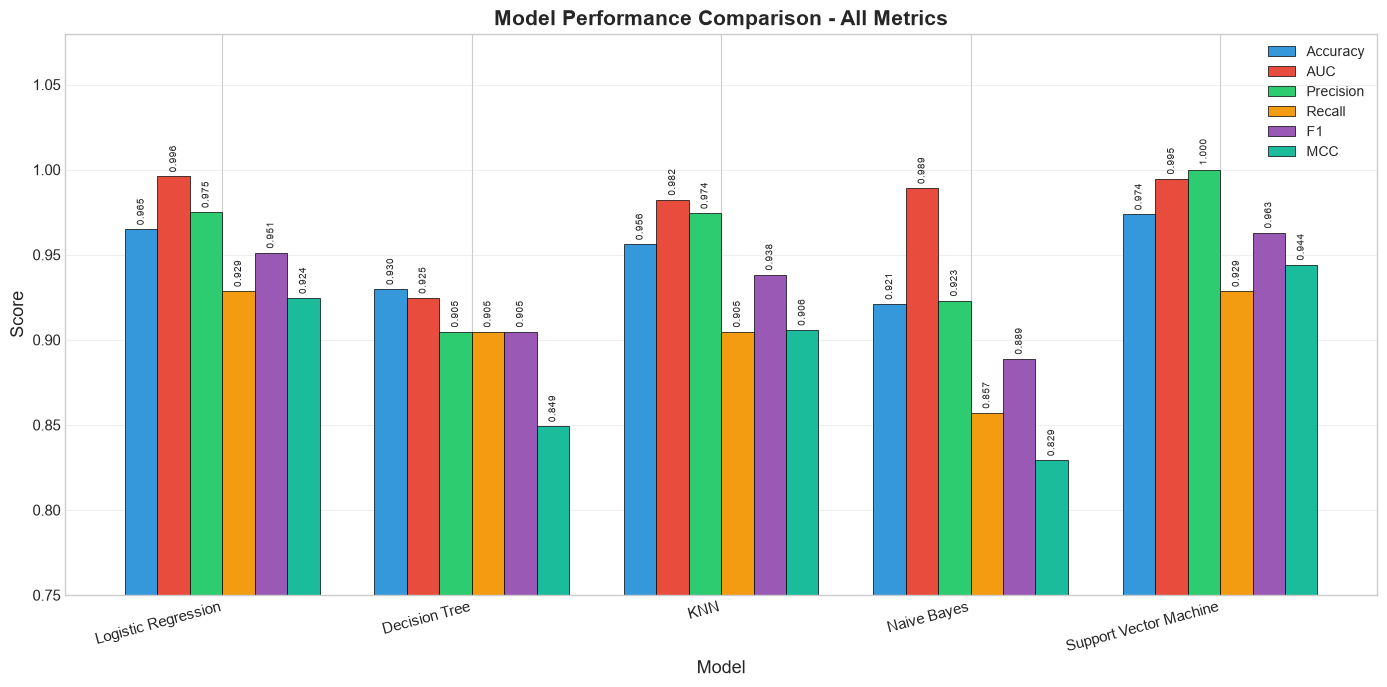

In [22]:
fig, ax = plt.subplots(figsize=(14, 7))

x = np.arange(len(comparison_df.index))
width = 0.13
colors = ['#3498db', '#e74c3c', '#2ecc71', '#f39c12', '#9b59b6', '#1abc9c']

for i, (metric, color) in enumerate(zip(comparison_df.columns, colors)):
    bars = ax.bar(x + i * width, comparison_df[metric], width, label=metric, color=color, edgecolor='black', linewidth=0.5)
    # Add value labels on bars
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{height:.3f}', xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=7, rotation=90)

ax.set_xlabel('Model', fontsize=13)
ax.set_ylabel('Score', fontsize=13)
ax.set_title('Model Performance Comparison - All Metrics', fontsize=15, fontweight='bold')
ax.set_xticks(x + width * 2.5)
ax.set_xticklabels(comparison_df.index, rotation=15, ha='right', fontsize=11)
ax.set_ylim(0.75, 1.08)
ax.legend(loc='upper right', fontsize=10)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

### 6.3 Individual Metric Comparison

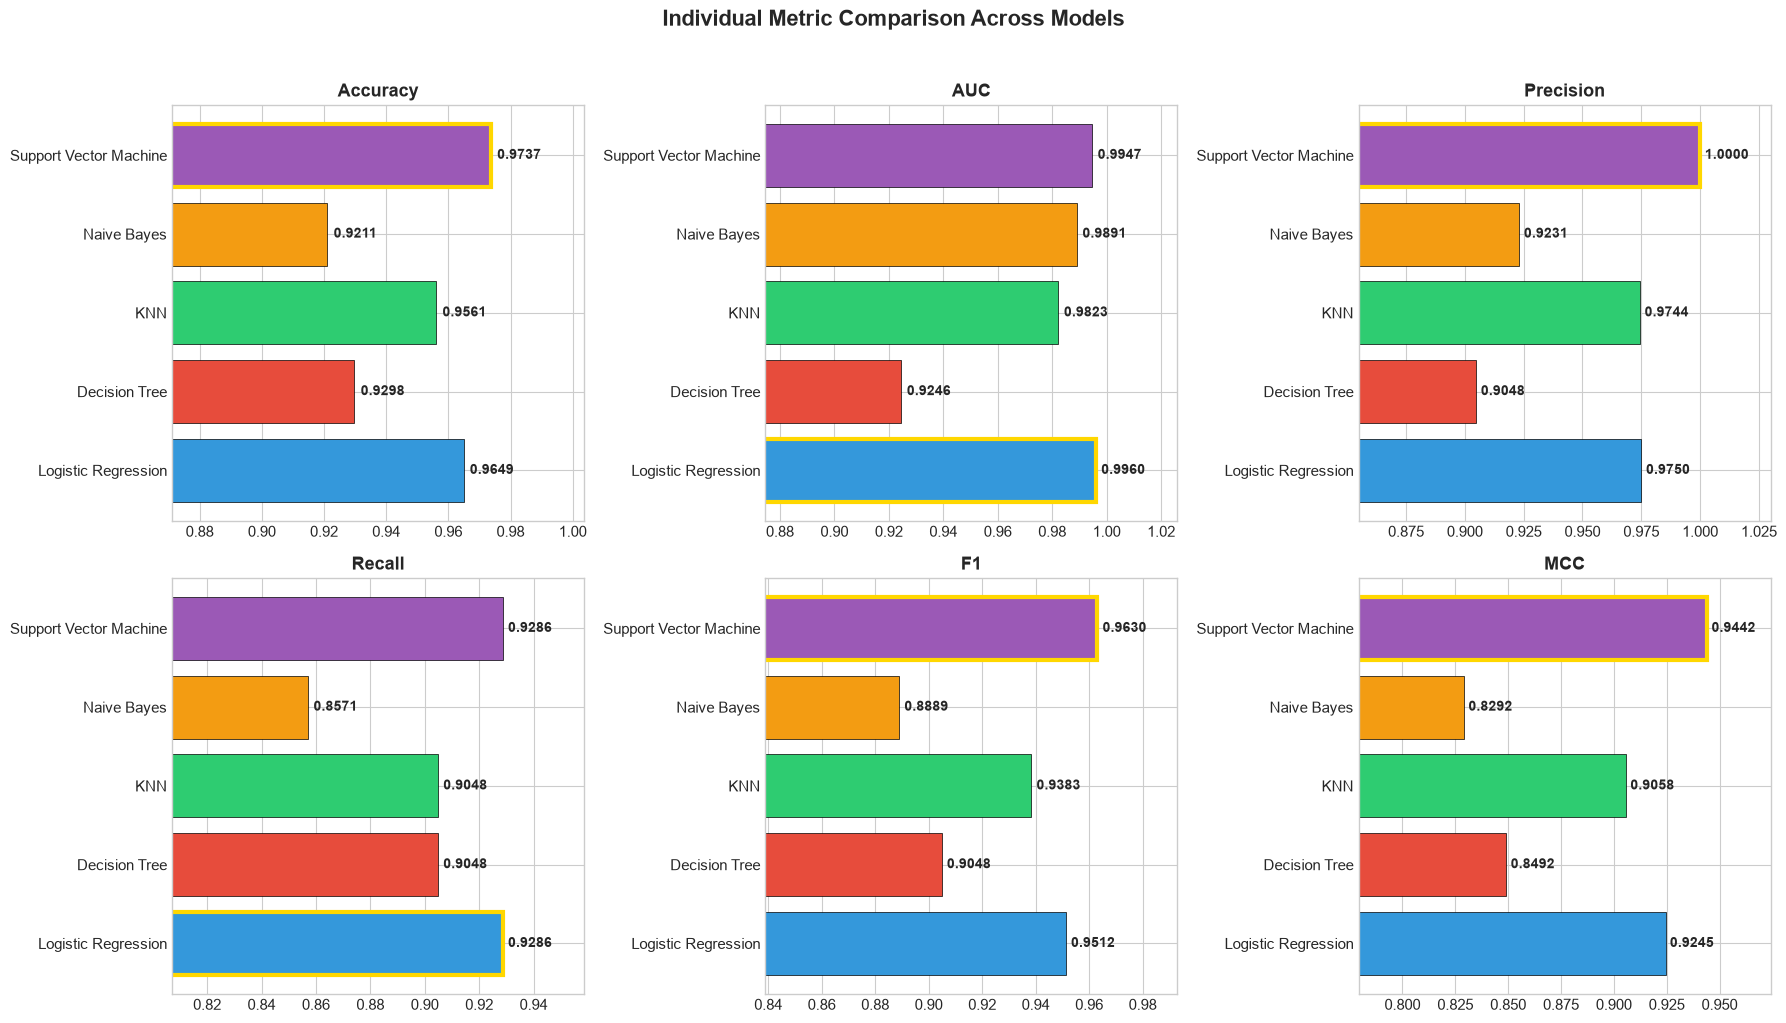

In [23]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()
model_colors = ['#3498db', '#e74c3c', '#2ecc71', '#f39c12', '#9b59b6']

for i, metric in enumerate(comparison_df.columns):
    values = comparison_df[metric].values
    bars = axes[i].barh(comparison_df.index, values, color=model_colors, edgecolor='black', linewidth=0.5)
    axes[i].set_title(metric, fontsize=13, fontweight='bold')
    axes[i].set_xlim(min(values) - 0.05, max(values) + 0.03)
    
    # Add value labels
    for bar, val in zip(bars, values):
        axes[i].text(val + 0.002, bar.get_y() + bar.get_height()/2,
                     f'{val:.4f}', va='center', fontsize=10, fontweight='bold')
    
    # Highlight the best
    best_idx = np.argmax(values)
    bars[best_idx].set_edgecolor('gold')
    bars[best_idx].set_linewidth(3)

plt.suptitle('Individual Metric Comparison Across Models', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 6.4 Confusion Matrices - All Models

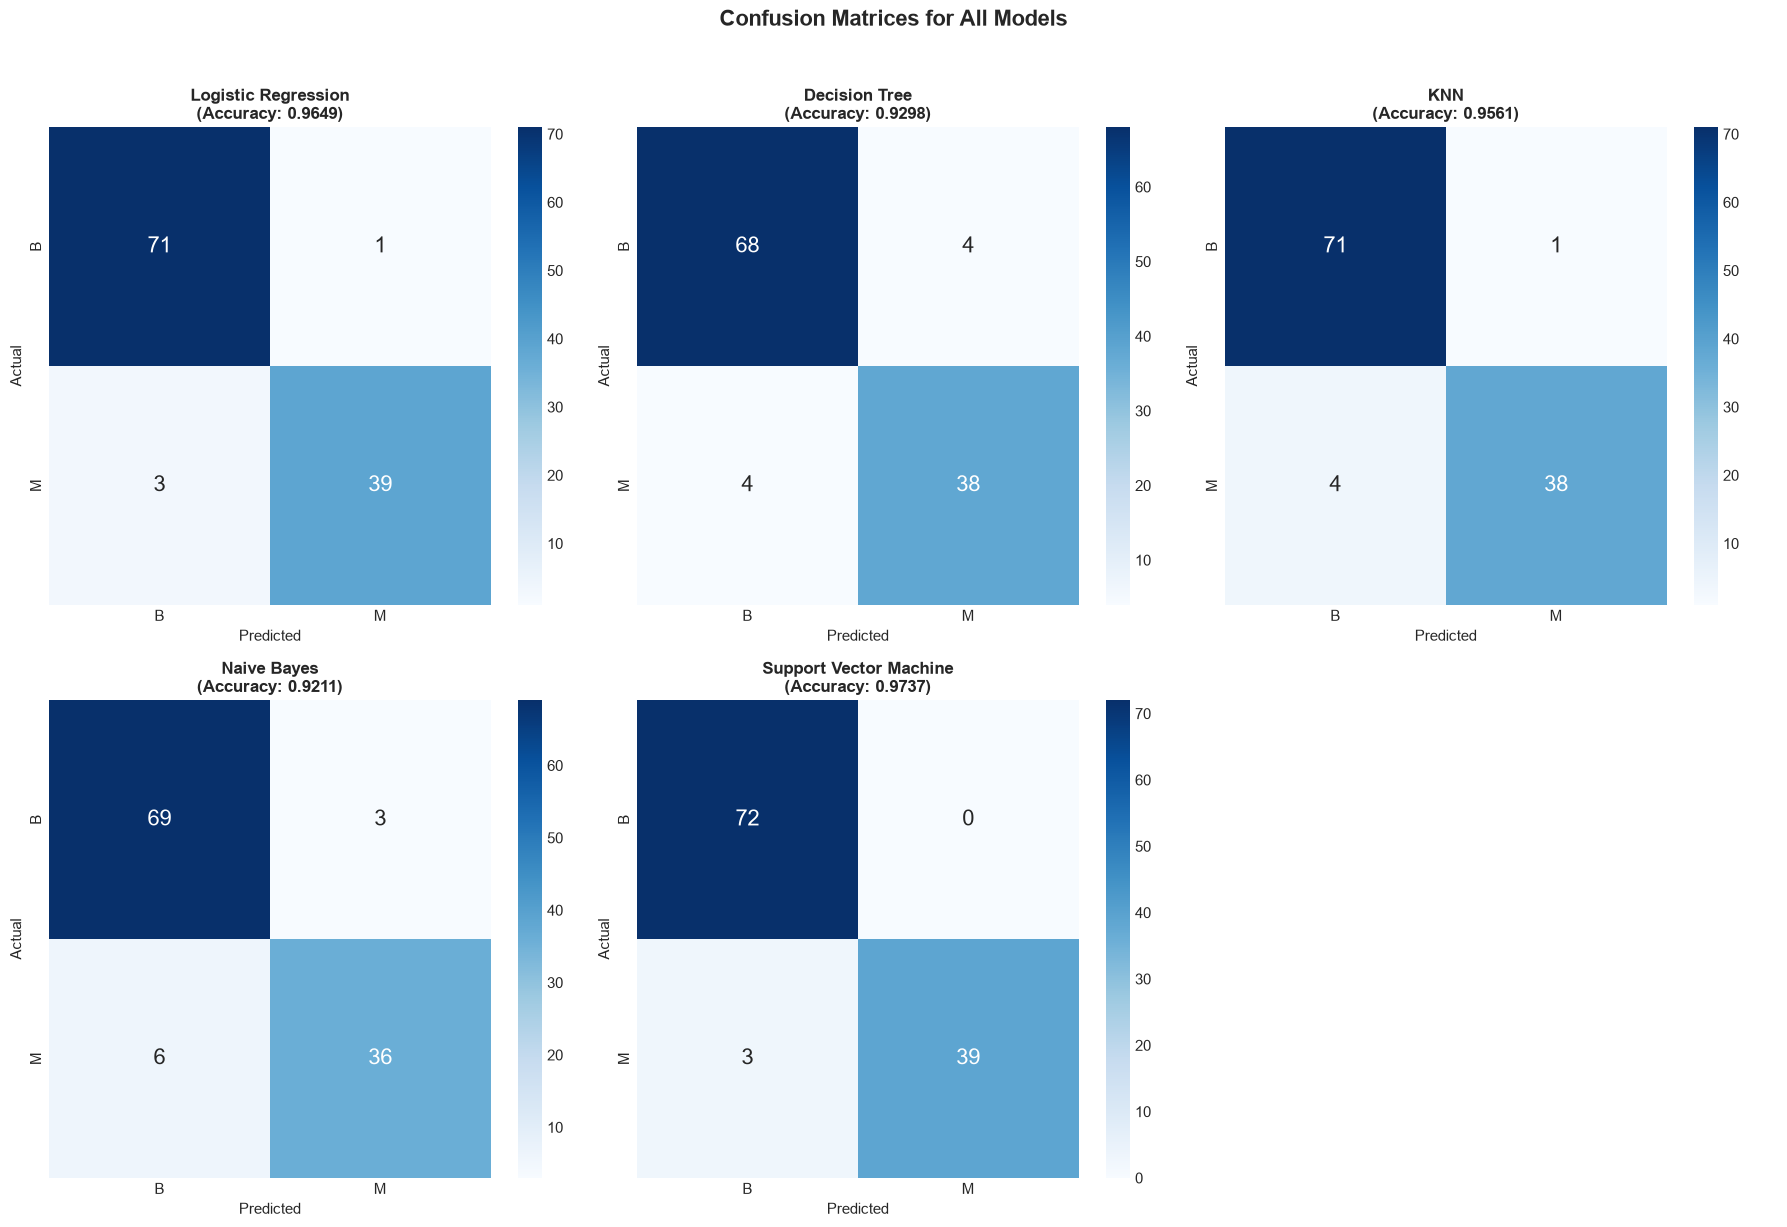

In [24]:
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for idx, (name, y_pred) in enumerate(predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=le.classes_, yticklabels=le.classes_,
                ax=axes[idx], annot_kws={'size': 16})
    axes[idx].set_title(f'{name}\n(Accuracy: {results[name]["Accuracy"]:.4f})',
                        fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('Predicted', fontsize=11)
    axes[idx].set_ylabel('Actual', fontsize=11)

# Hide the empty 6th subplot
axes[5].axis('off')

plt.suptitle('Confusion Matrices for All Models', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 6.5 ROC Curves - All Models

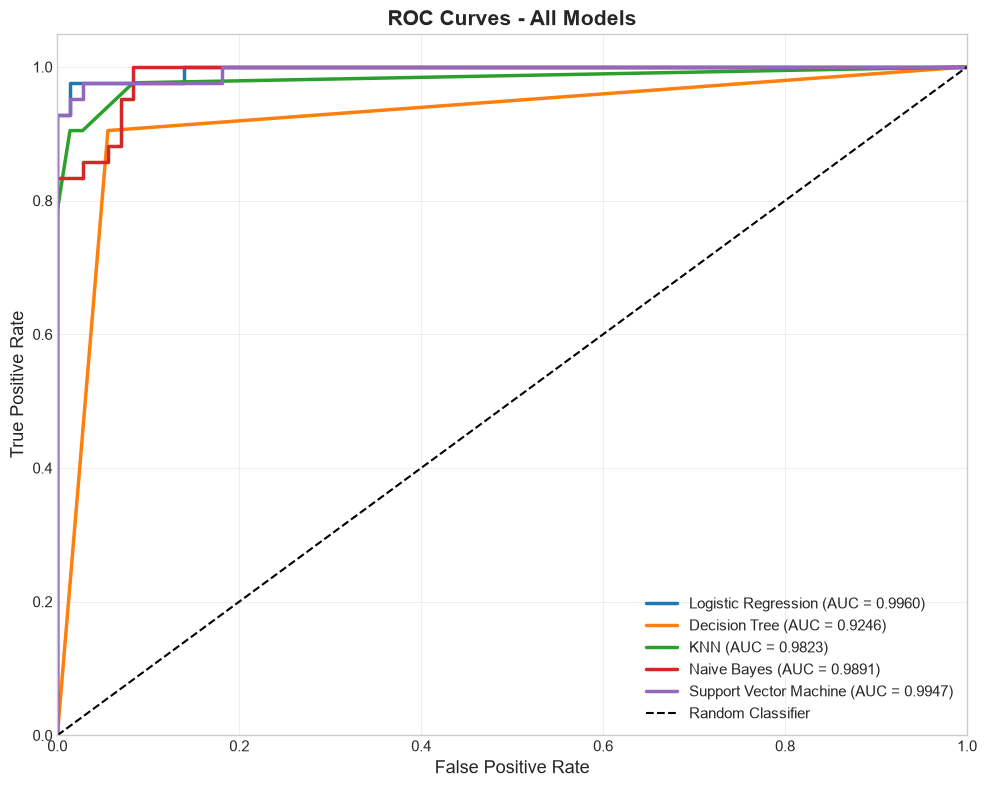

In [25]:
fig, ax = plt.subplots(figsize=(10, 8))
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']

for (name, y_prob), color in zip(probabilities.items(), colors):
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_val = roc_auc_score(y_test, y_prob)
    ax.plot(fpr, tpr, color=color, lw=2.5, label=f'{name} (AUC = {auc_val:.4f})')

ax.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Classifier')
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel('False Positive Rate', fontsize=13)
ax.set_ylabel('True Positive Rate', fontsize=13)
ax.set_title('ROC Curves - All Models', fontsize=15, fontweight='bold')
ax.legend(loc='lower right', fontsize=11, framealpha=0.9)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 6.6 Individual ROC Curves

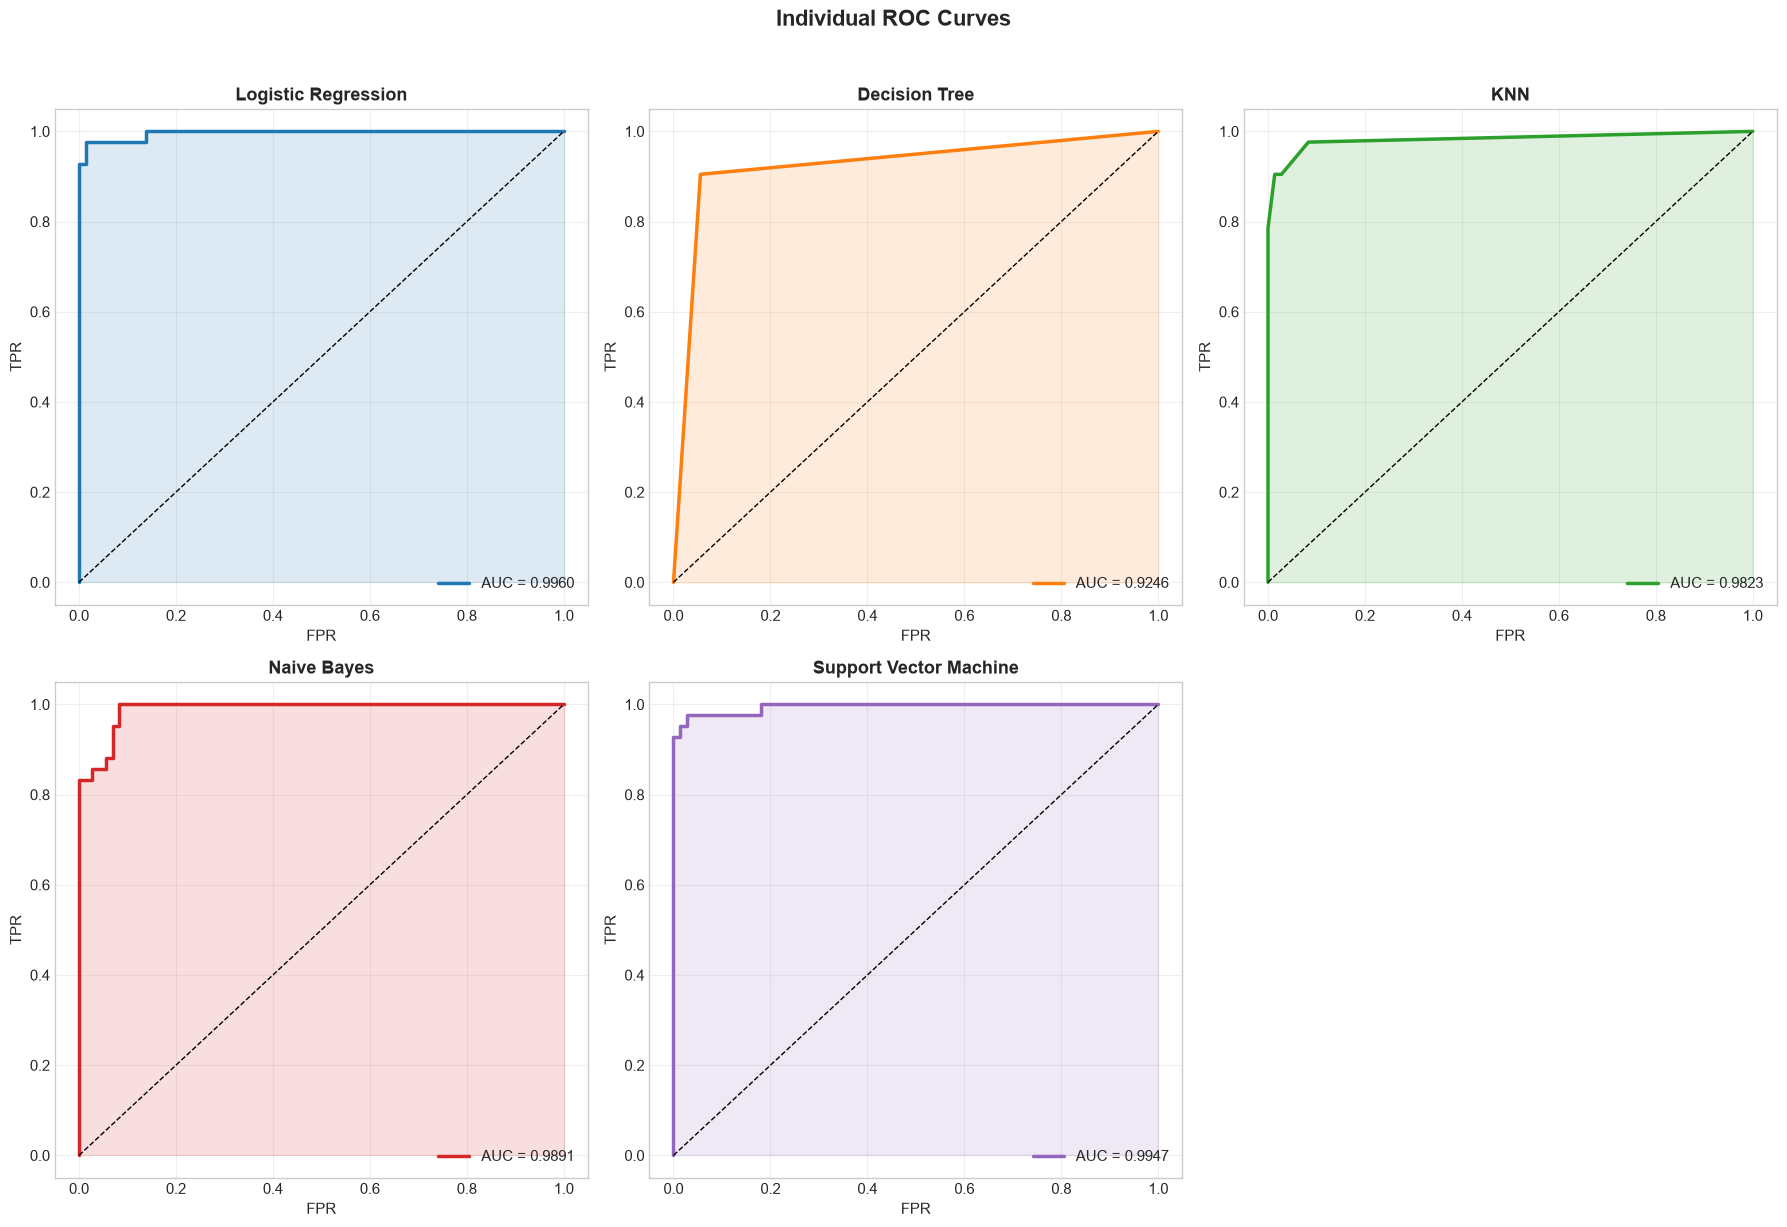

In [26]:
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']

for idx, ((name, y_prob), color) in enumerate(zip(probabilities.items(), colors)):
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_val = roc_auc_score(y_test, y_prob)
    
    axes[idx].plot(fpr, tpr, color=color, lw=2.5, label=f'AUC = {auc_val:.4f}')
    axes[idx].plot([0, 1], [0, 1], 'k--', lw=1)
    axes[idx].fill_between(fpr, tpr, alpha=0.15, color=color)
    axes[idx].set_title(name, fontsize=13, fontweight='bold')
    axes[idx].set_xlabel('FPR', fontsize=11)
    axes[idx].set_ylabel('TPR', fontsize=11)
    axes[idx].legend(loc='lower right', fontsize=11)
    axes[idx].grid(alpha=0.3)

axes[5].axis('off')

plt.suptitle('Individual ROC Curves', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 6.7 Radar Chart - Model Comparison

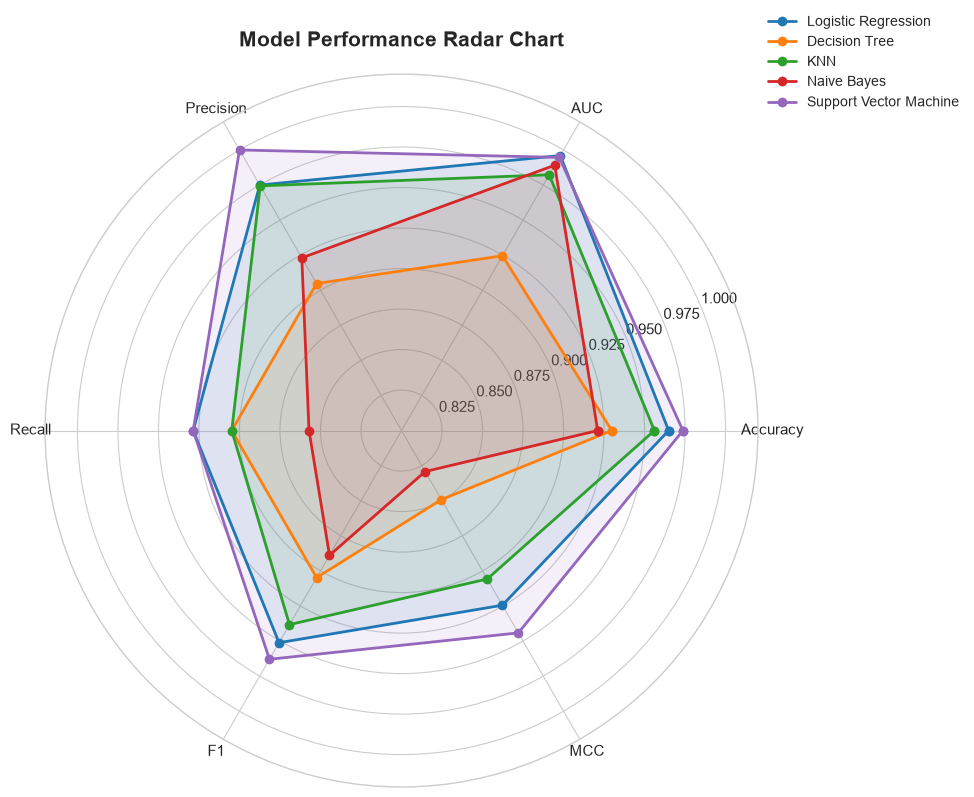

In [27]:
# Radar chart for model comparison
categories = list(comparison_df.columns)
N = len(categories)
angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]  # close the polygon

fig, ax = plt.subplots(figsize=(10, 10), subplot_kw=dict(polar=True))
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']

for i, (name, row) in enumerate(comparison_df.iterrows()):
    values = row.values.tolist()
    values += values[:1]  # close the polygon
    ax.plot(angles, values, 'o-', linewidth=2, label=name, color=colors[i])
    ax.fill(angles, values, alpha=0.1, color=colors[i])

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=11)
ax.set_ylim(0.8, 1.02)
ax.set_title('Model Performance Radar Chart', fontsize=15, fontweight='bold', pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), fontsize=10)
ax.grid(True)

plt.tight_layout()
plt.show()

### 6.8 Accuracy Ranking

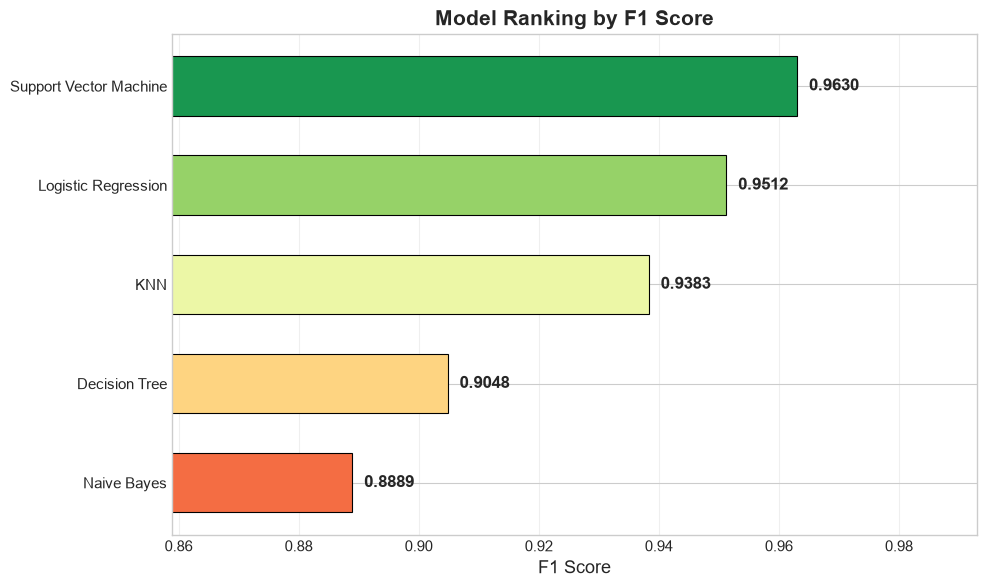

In [28]:
# Sort models by F1 score
sorted_models = comparison_df.sort_values('F1', ascending=True)

fig, ax = plt.subplots(figsize=(10, 6))
colors_sorted = ['#e74c3c' if i < len(sorted_models)-1 else '#2ecc71' for i in range(len(sorted_models))]
colors_sorted = plt.cm.RdYlGn(np.linspace(0.2, 0.9, len(sorted_models)))

bars = ax.barh(sorted_models.index, sorted_models['F1'], color=colors_sorted, edgecolor='black', linewidth=0.8, height=0.6)

for bar, val in zip(bars, sorted_models['F1']):
    ax.text(val + 0.002, bar.get_y() + bar.get_height()/2,
            f'{val:.4f}', va='center', fontsize=12, fontweight='bold')

ax.set_xlabel('F1 Score', fontsize=13)
ax.set_title('Model Ranking by F1 Score', fontsize=15, fontweight='bold')
ax.set_xlim(min(sorted_models['F1']) - 0.03, max(sorted_models['F1']) + 0.03)
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

## 7. Observations & Conclusion

### Model-wise Observations

| Model | Observation |
|---|---|
| **Logistic Regression** | Performs excellently with 96.49% accuracy and AUC of 0.9960 (near-perfect). Strong balance between precision (0.9750) and recall (0.9286), yielding F1 = 0.9512. Benefits from linearly separable features and feature scaling. Misclassified only 4 samples. Reliable and interpretable. |
| **Decision Tree** | Second-lowest performance at 92.98% accuracy. Equal precision and recall (0.9048) with lowest AUC (0.9246). Made 8 misclassifications. Prone to overfitting without pruning or ensemble methods, but offers good interpretability. |
| **KNN** | Achieves 95.61% accuracy with very high precision (0.9744) but lower recall (0.9048) - conservative in predicting malignancy. AUC of 0.9823 shows strong discrimination. Benefits significantly from StandardScaler preprocessing as a distance-based algorithm. |
| **Naive Bayes** | Lowest accuracy (92.11%) and F1 (0.8889). However, surprisingly high AUC (0.9891), indicating well-calibrated probability estimates. Lower recall (0.8571) means it misses more malignant cases - a concern in medical diagnosis. Feature independence assumption may not hold perfectly. |
| **Support Vector Machine** | **Best model** with highest accuracy (97.37%), F1 (0.9630), and MCC (0.9442). Achieves **perfect precision (1.0000)** with zero false positives, while maintaining strong recall (0.9286). RBF kernel effectively captures non-linear decision boundary. Only 3 misclassifications. |

### Conclusion

**Support Vector Machine (SVM)** is the clear winner for the Breast Cancer Wisconsin dataset. It achieves the highest scores across nearly all metrics. In a medical diagnosis context, having zero false positives is particularly valuable. **Logistic Regression** is a close second and offers better interpretability, making it a strong alternative for clinical use.

In [29]:
# Final summary
print("="*70)
print("                    FINAL SUMMARY")
print("="*70)
print(f"\nDataset: Breast Cancer Wisconsin (Diagnostic)")
print(f"Samples: 569 (Train: 455, Test: 114)")
print(f"Features: 30 numeric features")
print(f"Classes: Benign (B=0), Malignant (M=1)")
print(f"\n{'Model':<25} {'F1 Score':>10} {'Accuracy':>10} {'AUC':>10}")
print("-"*60)
for name in sorted(results, key=lambda k: results[k]['F1'], reverse=True):
    m = results[name]
    marker = ' <<< BEST' if name == best_model else ''
    print(f"{name:<25} {m['F1']:>10.4f} {m['Accuracy']:>10.4f} {m['AUC']:>10.4f}{marker}")
print("="*70)
print(f"\nBest Model: {best_model}")
print(f"All models and artifacts saved in 'model/' directory.")

                    FINAL SUMMARY

Dataset: Breast Cancer Wisconsin (Diagnostic)
Samples: 569 (Train: 455, Test: 114)
Features: 30 numeric features
Classes: Benign (B=0), Malignant (M=1)

Model                       F1 Score   Accuracy        AUC
------------------------------------------------------------
Support Vector Machine        0.9630     0.9737     0.9947 <<< BEST
Logistic Regression           0.9512     0.9649     0.9960
KNN                           0.9383     0.9561     0.9823
Decision Tree                 0.9048     0.9298     0.9246
Naive Bayes                   0.8889     0.9211     0.9891

Best Model: Support Vector Machine
All models and artifacts saved in 'model/' directory.
